# Phase 5: descriptive spatial trends
Estimated change only. Inference is disabled after failed Phase 4 validation. Positive/negative/zero are numerical descriptions, never significance or stability labels. All prior data and preparation policies are preserved.

In [1]:
from pathlib import Path
import json
import xarray as xr
from IPython.display import display, Image
root=Path.cwd()
r=json.loads((root/'data/derived/science_spatial/phase_5/results.json').read_text())
print('Cases:',len(r['cases']), 'Inference:',r['inference_status'])
for c in r['cases']:
 print(c['key'], c['periods']['annual'][0]['slope_per_year'],c['periods']['annual'][0]['slope_units'])

Cases: 14 Inference: disabled_failed_validation
air_temperature__nile_corridor__strict_100 0.025330383313493597 K per year
soil_moisture__nile_corridor__strict_100 0.008890433836505951 kg m-2 per year
precipitation__nile_corridor__strict_100 0.027554997033746184 mm per year
vegetation_greenness__nile_corridor__strict_100 0.000123810554870301 1 per year
air_temperature__morocco_comparison__strict_100 0.033175364236687224 K per year
soil_moisture__morocco_comparison__strict_100 -0.12612017353263624 kg m-2 per year
precipitation__morocco_comparison__strict_100 -8.47735157908451 mm per year
vegetation_greenness__morocco_comparison__strict_100 -0.0003231025134762133 1 per year
air_temperature__sahel_comparison__strict_100 -0.023441037765244185 K per year
soil_moisture__sahel_comparison__strict_100 -0.026383741725966903 kg m-2 per year
precipitation__sahel_comparison__strict_100 2.6037411068641902 mm per year
vegetation_greenness__sahel_comparison__strict_100 0.0009737242896536887 1 per year

## Sahel NDVI: three preparation policies
Strict 100% remains default. Standard 100% is a fixed-support comparison. Standard 95% remains experimental: monthly geography changes and incomplete annual cell records remain missing. Gray in the slope map denotes unavailable slopes; consult the separate support map to distinguish exclusion. Shares use preparation-eligible cells including unavailable cells.

strict_100 eligible selected-area fraction: 0.1469480561054765


{'eligible_cells': 2961,
 'selected_cells': 20000,
 'excluded_cells': 17039,
 'counts': {'positive': 2878,
  'negative': 83,
  'exactly_zero': 0,
  'unavailable': 0},
 'percent_of_eligible_cells': {'positive': 97.1968929415738,
  'negative': 2.803107058426207,
  'exactly_zero': 0.0,
  'unavailable': 0.0},
 'denominator_definition': 'all preparation-eligible cells, including unavailable slopes'}

Missing eligible cell-years: 0


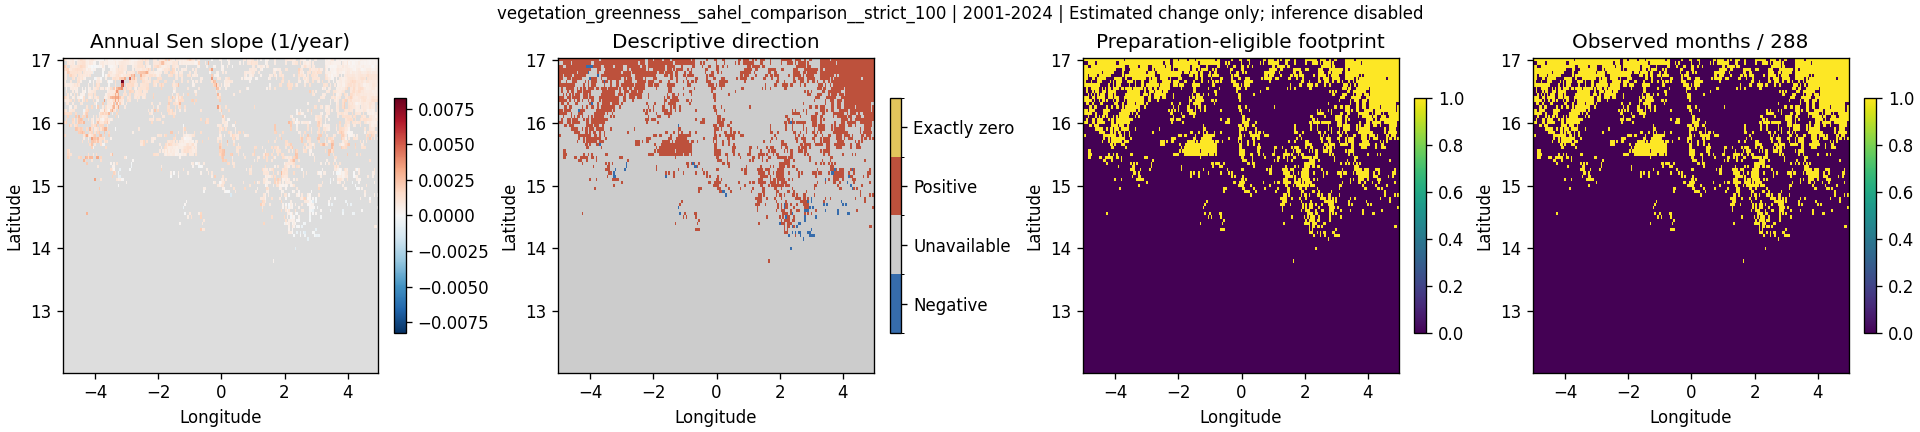

standard_100 eligible selected-area fraction: 0.8258686050073931


{'eligible_cells': 16531,
 'selected_cells': 20000,
 'excluded_cells': 3469,
 'counts': {'positive': 14035,
  'negative': 2496,
  'exactly_zero': 0,
  'unavailable': 0},
 'percent_of_eligible_cells': {'positive': 84.90109491258848,
  'negative': 15.09890508741153,
  'exactly_zero': 0.0,
  'unavailable': 0.0},
 'denominator_definition': 'all preparation-eligible cells, including unavailable slopes'}

Missing eligible cell-years: 0


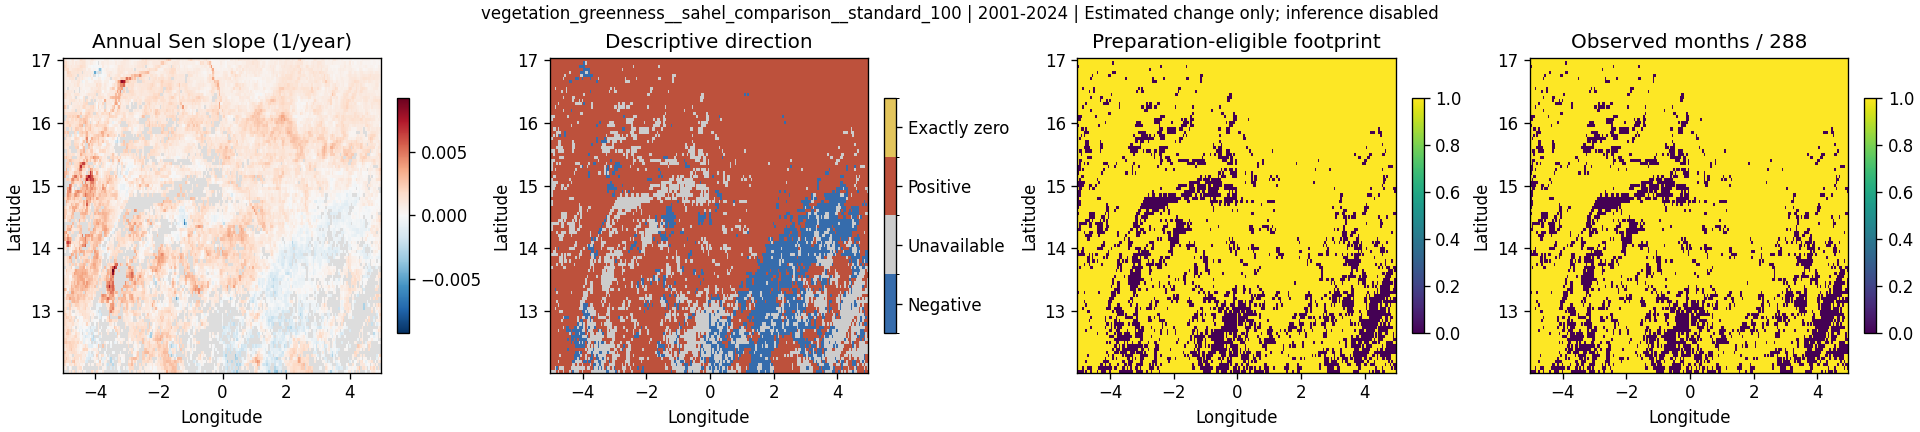

standard_95 eligible selected-area fraction: 0.999751475142648


{'eligible_cells': 19995,
 'selected_cells': 20000,
 'excluded_cells': 5,
 'counts': {'positive': 16436,
  'negative': 3559,
  'exactly_zero': 0,
  'unavailable': 0},
 'percent_of_eligible_cells': {'positive': 82.20055013753438,
  'negative': 17.799449862465618,
  'exactly_zero': 0.0,
  'unavailable': 0.0},
 'denominator_definition': 'all preparation-eligible cells, including unavailable slopes'}

Missing eligible cell-years: 5157


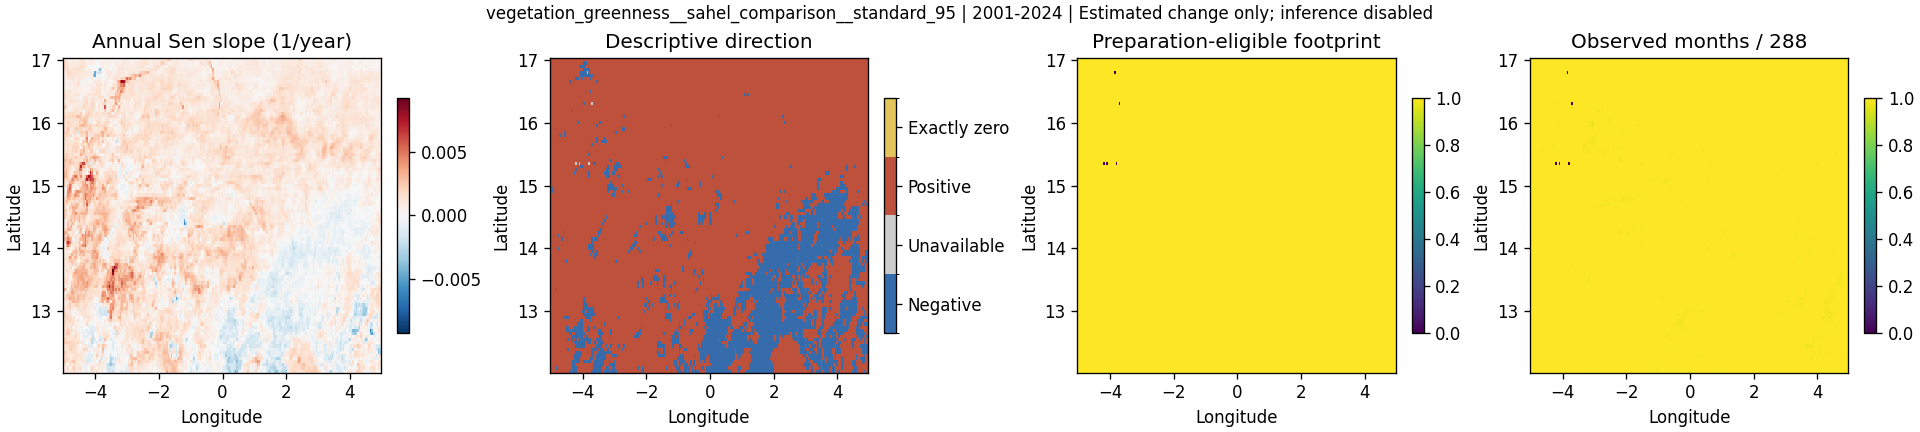

[{'baseline': 'strict_100',
  'candidate': 'standard_100',
  'common_cells': 2961,
  'gained_cells': 13570,
  'lost_cells': 0,
  'common_computable_annual_cells': 2961,
  'mean_annual_slope_difference_common_cells': 0.0,
  'interpretation': 'different supports are not interchangeable; regional differences combine location selection and preparation',
  'location_artifact': 'data/derived/science_spatial/phase_5/standard_100_vs_strict_100.nc'},
 {'baseline': 'standard_100',
  'candidate': 'standard_95',
  'common_cells': 16531,
  'gained_cells': 3464,
  'lost_cells': 0,
  'common_computable_annual_cells': 16531,
  'mean_annual_slope_difference_common_cells': 0.0,
  'interpretation': 'different supports are not interchangeable; regional differences combine location selection and preparation',
  'location_artifact': 'data/derived/science_spatial/phase_5/standard_95_vs_standard_100.nc'}]

In [2]:
sahel=[c for c in r['cases'] if c['variable_id']=='vegetation_greenness' and c['region_id']=='sahel_comparison']
for c in sahel:
 print(c['policy'],'eligible selected-area fraction:',c['eligible_area_fraction_selected'])
 display(c['periods']['annual'][0]['cell_shares'])
 print('Missing eligible cell-years:',c['annual_missing_eligible_cell_years'])
 display(Image(filename=str(root/c['map_artifact'])))
display(r['policy_comparisons'])

## Period sensitivity
Every period is compared to its own actual 2001–2024 reference. Eligibility remains fixed. These windows are descriptive; short records and raw monthly seasonality limit interpretation. Regional slopes are computed from the regional series, not the average cell slope.

In [3]:
for c in sahel:
 print(c['policy'])
 for p in c['periods']['annual']:
  display({k:p[k] for k in ['start_year','end_year','n_valid','valid_span_years','slope_per_year','regional_direction_agrees_full_period']})
with xr.open_dataset(root/sahel[-1]['grid_artifact']) as grid:
 display(grid)
 print('Unavailable comparison code:',-1)

strict_100


{'start_year': 2001,
 'end_year': 2024,
 'n_valid': 24,
 'valid_span_years': 23.0,
 'slope_per_year': 0.0009737242896536887,
 'regional_direction_agrees_full_period': True}

{'start_year': 2001,
 'end_year': 2012,
 'n_valid': 12,
 'valid_span_years': 11.0,
 'slope_per_year': 0.0008044160024201844,
 'regional_direction_agrees_full_period': True}

{'start_year': 2013,
 'end_year': 2024,
 'n_valid': 12,
 'valid_span_years': 11.0,
 'slope_per_year': 0.002324337913541765,
 'regional_direction_agrees_full_period': True}

{'start_year': 2005,
 'end_year': 2024,
 'n_valid': 20,
 'valid_span_years': 19.0,
 'slope_per_year': 0.0011683127698344123,
 'regional_direction_agrees_full_period': True}

standard_100


... (7 outputs left out)

{'start_year': 2013,
 'end_year': 2024,
 'n_valid': 12,
 'valid_span_years': 11.0,
 'slope_per_year': 0.002120602350212593,
 'regional_direction_agrees_full_period': True}

{'start_year': 2005,
 'end_year': 2024,
 'n_valid': 20,
 'valid_span_years': 19.0,
 'slope_per_year': 0.0010261402555858312,
 'regional_direction_agrees_full_period': True}

<xarray.Dataset> Size: 6MB
Dimensions:                               (lat: 100, lon: 200, window: 4)
Coordinates:
  * lat                                   (lat) float64 800B 12.05 12.1 ... 17.0
  * lon                                   (lon) float64 2kB -5.0 -4.95 ... 4.95
  * window                                (window) <U9 144B '2001_2024' ... '...
Data variables: (12/17)
    eligible_support                      (lat, lon) int8 20kB ...
    native_cell_solid_angle               (lat, lon) float64 160kB ...
    monthly_slope                         (window, lat, lon) float64 640kB ...
    monthly_n_valid                       (window, lat, lon) int64 640kB ...
    monthly_valid_span_years              (window, lat, lon) float64 640kB ...
    monthly_pair_count                    (window, lat, lon) int64 640kB ...
    ...                                    ...
    annual_valid_span_years               (window, lat, lon) float64 640kB ...
    annual_pair_count                     (window, lat, lon) int64 640kB ...
    annual_computable                     (window, lat, lon) int8 80kB ...
    annual_direction                      (window, lat, lon) int8 80kB ...
    annual_direction_agrees_full_period   (window, lat, lon) int8 80kB ...
    monthly_observed_fraction             (lat, lon) float64 160kB ...
Attributes:
    method:                  exact descriptive Theil-Sen; min_points=3 comput...
    policy:                  standard_95
    experimental:            1
    source_prepared_sha256:  80ec75ff4fe2359f753a109586c10cc938d266ff18183cb5...
    inference_status:        disabled_failed_validation
    estimated_change_only:   1
    time_units:              calendar-month ordinal difference / 12; actual a...
    limitations:             No demonstrated significance, stability or causa...

Unavailable comparison code: -1


## Boundary
No p-values, confidence intervals, FDR, causal claims or statistically demonstrated changes are published. Policy/location differences are not interchangeable estimates or uncertainty intervals. Stop at Phase 5 for owner review before Phase 6.